<a href="https://colab.research.google.com/github/Srasti05/4IK25CS203_DAV_LAB/blob/main/4IK25CS203_EXP_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

LAB-7 Simple and Multiple Linear Regression :Building models,checking assumptions, and evaluating using R2 and RMSE

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

Load and clean data

In [ ]:
df = pd.read_csv('/content/Titanic-Dataset.csv')
df = df[['Fare', 'Pclass', 'Age', 'SibSp','Parch']]
df['Age'] = df['Age'].fillna(df['Age'].median())
df = df[df['Fare'] > 0]

Simple and Linear Regression

In [ ]:
X_simple = df[['Pclass']]
y=df['Fare']
X_tr,X_te,y_tr,y_te=train_test_split(X_simple,y,test_size=0.2,random_state=42)
model_simple = LinearRegression().fit(X_tr, y_tr)
pred_simple= model_simple.predict(X_te)
print("SIMPLE Regression -- Intercept:",round(model_simple.intercept_,2))
print("SIMPLE Regression -- Slope:",round(model_simple.coef_[0],2))
print("SIMPLE Regression -- R2:",round(r2_score(y_te,pred_simple),3))
print("SIMPLE Regression -- RMSE:",round(np.sqrt(mean_squared_error(y_te,pred_simple)),2))

SIMPLE Regression -- Intercept: 112.38
SIMPLE Regression -- Slope: -34.23
SIMPLE Regression -- R2: 0.371
SIMPLE Regression -- RMSE: 35.68


Mutiple Linear Regression (many features)

In [ ]:
X_multi = df[['Pclass', 'Age', 'SibSp','Parch']]
X_tr2,X_te2,y_tr2,y_te2 = train_test_split(X_multi,y,test_size=0.2,random_state=42)
model_multi = LinearRegression().fit(X_tr2, y_tr2)
pred_multi= model_multi.predict(X_te2)
print('\nMUTIPLE Regression -- Intercept:',round(model_multi.intercept_,2))
for name,coef in zip(X_multi.columns,model_multi.coef_):
  print('MUTIPLE Regression --Coefficient of',name,':', round(coef,2))
print("MUTIPLE Regression -- R2:",round(r2_score(y_te2,pred_multi),3))
print("MUTIPLE Regression -- RMSE:",round(np.sqrt(mean_squared_error(y_te2,pred_multi)),2))



MUTIPLE Regression -- Intercept: 112.3
MUTIPLE Regression --Coefficient of Pclass : -35.72
MUTIPLE Regression --Coefficient of Age : -0.12
MUTIPLE Regression --Coefficient of SibSp : 5.38
MUTIPLE Regression --Coefficient of Parch : 10.09
MUTIPLE Regression -- R2: 0.462
MUTIPLE Regression -- RMSE: 33.0


Plot: Simple regression line

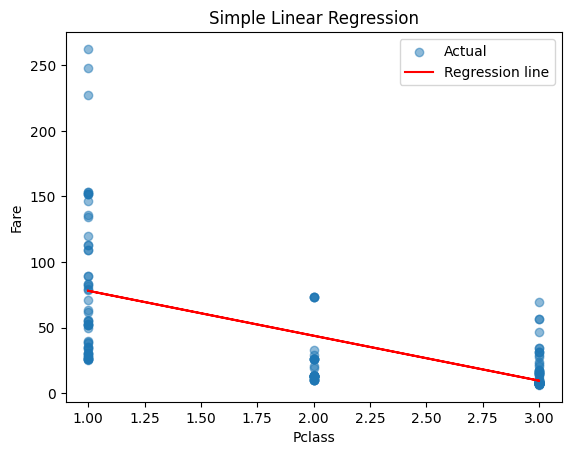

In [ ]:
plt.scatter(X_te,y_te,alpha=0.5,label='Actual')
plt.plot(X_te,pred_simple,color='red',label='Regression line')
plt.xlabel('Pclass'); plt.ylabel('Fare');plt.title('Simple Linear Regression')
plt.legend()
plt.show()

Checking assumption (Multiple Regression)
  1.Linearity and equal variance

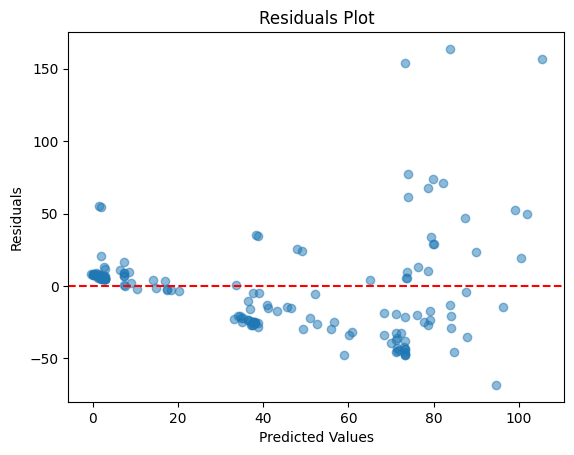

In [ ]:
residuals = y_te2 - pred_multi
plt.scatter(pred_multi, residuals,alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Values');plt.ylabel('Residuals');plt.title('Residuals Plot')
plt.show()

2.Normality :residual should look roughly bell -shaped

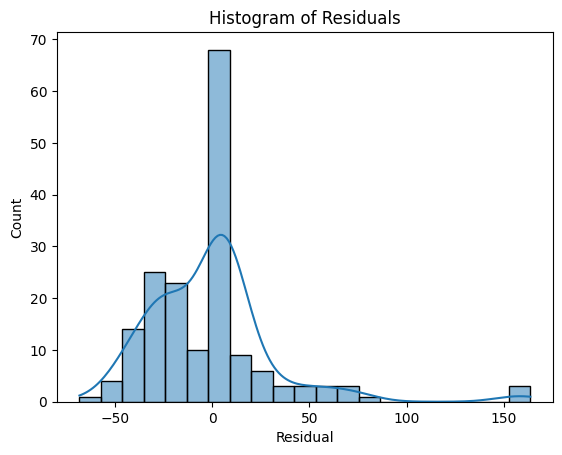

In [ ]:
sns.histplot(residuals,kde=True)
plt.xlabel('Residual');plt.title('Histogram of Residuals')
plt.show()

Multicoli

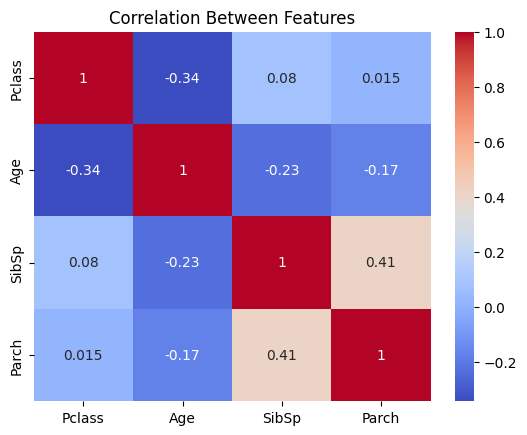

In [ ]:
sns.heatmap(X_multi.corr(),annot=True,cmap='coolwarm')
plt.title('Correlation Between Features')
plt.show()